# Mapa de fluxo — Migração de e para a Bahia (Censo 2022)
**Disciplina:** Visualização de Dados · **Capítulo 7 (Geoespacial)** de Schwabish, *Better Data Visualizations* · **Técnica 4 de 4**

> **Pergunta de pesquisa:** de quais Unidades da Federação vêm, e para quais vão, as pessoas que mudam de UF de e para a Bahia?

**Dados:** IBGE, Censo Demográfico 2022, Tabela SIDRA 10159 (migração por data fixa: UF de residência em 31/07/2022 × UF de residência cinco anos antes). **Tipo de mapa:** fluxo radial (origem-destino), com a Bahia no centro. **Regras visuais:** só os maiores fluxos, largura proporcional ao número de pessoas, cinza com um único destaque.

## 1. O que é
Um **mapa de fluxo** mostra movimento entre lugares: linhas ou setas indicam a direção e a **largura** da linha pode ser proporcional ao valor (Schwabish, p. 245). O livro distingue:

| Tipo | Como funciona | Exemplo do livro |
|---|---|---|
| **Radial / origem-destino** | fluxos de uma origem para vários destinos (ou o inverso) | **nosso caso:** Bahia ↔ 26 UFs |
| Distributivo | o fluxo de uma origem se ramifica em várias linhas | mapa de rotas da Delta Air Lines |
| Narrativo | largura = quantidade, com outras variáveis na mesma imagem | mapas de Minard (Napoleão e Aníbal) |

Elementos visuais: **nós** (lugares), **linhas** retas (ligações), **largura** (volume), **cor** (aqui, só para destacar) e **marcador de direção**.

## 2. Quando usar
- **Pergunta que responde:** "de onde para onde as coisas (pessoas, mercadorias, voos) se movem, e quais ligações dominam?"
- **Use quando** a relação origem-destino é o assunto e o leitor entende o território (o livro lembra que o público precisa conhecer a geografia).
- **Evite quando** há muitos pares origem-destino e o objetivo é ler valores exatos: o emaranhado (espaguete) esconde as diferenças. Nesse caso, filtre os maiores fluxos, como fazemos aqui, ou use barras.

## 3. Como ler
1. **O ponto central** é a Bahia; os outros pontos são as UFs.
2. **A direção** está no marcador triangular no meio de cada linha: no mapa 1 aponta para a Bahia (entradas); no mapa 2, para fora (saídas).
3. **A largura** é proporcional ao número de pessoas, **na mesma escala nos dois mapas**; a chave "50 mil pessoas" mostra a referência.
4. **O laranja** é só o maior fluxo; todo o resto é cinza.
5. **A linha reta não é uma rota:** liga pontos representativos das UFs.

## 4. Do livro ao nosso dado
### 4.1 O exemplo do livro (Schwabish, p. 245–248)

O livro mostra dois mapas de fluxo: (a) o **mapa de rotas da Delta**, um fluxo distributivo que parece confuso, mas cumpre o objetivo da empresa de mostrar "cobertura inigualável"; (b) o **mapa de Minard** da campanha de Napoleão na Rússia (1812–1813), que integra seis variáveis (número de tropas pela largura, distância, temperatura, tempo, direção e geografia) e mostra a queda de cerca de 420.000 homens para cerca de 10.000.

**O que levamos para o nosso dado:** a largura proporcional à quantidade e a mensagem única (como em Minard, uma variável domina: o número de pessoas). **O que não levamos:** a Delta usa o emaranhado de propósito; nós, não, porque queremos que o leitor ache os fluxos que dominam.

### 4.2 Preparação

In [1]:
# Dependências: pandas, openpyxl, matplotlib, geopandas (ver requirements.txt)
import re, textwrap, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# ---- Identidade visual do professor: fundo branco, UMA cor de destaque, Calibri ----
BG, TXT, CINZA, CINZA_ESC, DESTAQUE = '#FFFFFF', '#262626', '#8C8C8C', '#BDBDBD', '#F28C28'
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Calibri', 'Carlito', 'DejaVu Sans'],  # fallback se Calibri não existir
    'figure.facecolor': BG, 'axes.facecolor': BG, 'savefig.facecolor': BG,
    'text.color': TXT, 'axes.labelcolor': TXT, 'xtick.color': CINZA, 'ytick.color': CINZA,
})
FONTE = 'Fonte: IBGE, Censo Demográfico 2022, Tabela 10159 (resultados preliminares da amostra). Elaboração própria.'
Path('figs').mkdir(exist_ok=True)

# ---- Arquivos e parâmetros ----
DADOS         = Path('dados')
ARQ_TABELA    = DADOS / 'tabela10159.xlsx'      # SIDRA 10159
ARQ_UF        = DADOS / 'BR_UF_2022.shp'        # IBGE > Malhas Territoriais > Brasil > UFs 2022 (opcional, ver 4.4)
CRS_MAPA      = 'EPSG:5880'                      # SIRGAS 2000 / Brasil Policônico (metros)
DATA_ACESSO   = '16/11/2026'
BAHIA         = 'Bahia'
TOP_N         = 12                               # quantos fluxos cada mapa mostra
LARGURA_MAX   = 12.0                             # largura (pt) do MAIOR fluxo dos dois mapas
AJUSTES_PADRAO = {'DF': (0, -14)}                # afasta rótulos de UFs muito próximas: {sigla: (dx, dy)} em pontos

### 4.3 Leitura da Tabela 10159
Nas **linhas**: UF de residência na data de referência (31/07/2022). Nas **colunas**: lugar de residência cinco anos antes. Logo, a **linha da Bahia = entradas** e a **coluna da Bahia = saídas**. O hífen da tabela é zero absoluto; `X` (valor inibido) e `..`/`...` viram vazio. O cabeçalho e o rodapé são localizados pelo texto, não por números de linha fixos.

In [2]:
bruta = pd.read_excel(ARQ_TABELA, sheet_name='Tabela', header=None)

linha_cab = bruta.index[bruta[1].eq('Rondônia')][0]                      # linha com os nomes das colunas
linha_fim = bruta.index[bruta[0].astype(str).str.startswith('Fonte')][0]  # rodapé 'Fonte: IBGE ...'
colunas = [c for c in bruta.iloc[linha_cab, 1:].tolist() if isinstance(c, str)]

dados = bruta.iloc[linha_cab + 1:linha_fim, :1 + len(colunas)].copy()
dados.columns = ['UF_atual'] + colunas
dados = dados.set_index('UF_atual')

# Conversão sem mexer em pontos/vírgulas (valores já são inteiros): '-' = 0; X, .., ... = vazio
matriz = dados.apply(lambda c: pd.to_numeric(c.replace({'-': 0, 'X': np.nan, '..': np.nan, '...': np.nan}), errors='coerce'))

UFS = [u for u in matriz.index]                                              # 27 UFs (linhas)
assert len(UFS) == 27 and BAHIA in UFS
assert (np.diag(matriz.loc[UFS, UFS].to_numpy()) == 0).all(), 'diagonal deveria ser zero: confira a orientação da matriz'
print(f'Matriz {matriz.shape} · valores vazios: {int(matriz.isna().sum().sum())}')

Matriz (27, 30) · valores vazios: 0


### 4.4 Entradas e saídas
`Exterior`, `Brasil sem especificação` e `Sem declaração` não são UFs e ficam fora dos mapas interestaduais. Os fluxos vão para duas tabelas no formato origem → destino.

In [3]:
OUTRAS = [u for u in UFS if u != BAHIA]

# Entradas: moravam na UF (coluna) cinco anos antes e moram na Bahia (linha) em 2022
entradas = pd.DataFrame({'origem': OUTRAS, 'destino': BAHIA, 'pessoas': matriz.loc[BAHIA, OUTRAS].to_numpy()})
# Saídas: moravam na Bahia (coluna) cinco anos antes e moram na UF (linha) em 2022
saidas = pd.DataFrame({'origem': BAHIA, 'destino': OUTRAS, 'pessoas': matriz.loc[OUTRAS, BAHIA].to_numpy()})

def so_positivos(df):
    return df.dropna(subset=['pessoas']).query('pessoas > 0').sort_values('pessoas', ascending=False).reset_index(drop=True)
entradas, saidas = so_positivos(entradas), so_positivos(saidas)

fluxos_entrada, fluxos_saida = entradas.head(TOP_N).copy(), saidas.head(TOP_N).copy()

# Escala ÚNICA para os dois mapas: pontos de largura por pessoa (largura proporcional, partindo de zero)
ESCALA = LARGURA_MAX / max(fluxos_entrada['pessoas'].max(), fluxos_saida['pessoas'].max())

# Números que sustentam as manchetes
for nome, tab, top in [('entradas', entradas, fluxos_entrada), ('saídas', saidas, fluxos_saida)]:
    print(f"{nome}: total {tab.pessoas.sum():,.0f} · maior fluxo {top.iloc[0, 0 if nome=='entradas' else 1]} = "
          f"{top.pessoas.iloc[0] / tab.pessoas.sum():.0%} · {TOP_N} maiores = {top.pessoas.sum() / tab.pessoas.sum():.0%} do total")

entradas: total 285,774 · maior fluxo São Paulo = 44% · 12 maiores = 91% do total
saídas: total 327,323 · maior fluxo São Paulo = 34% · 12 maiores = 91% do total


### 4.5 Geografia das UFs
O ideal é desenhar os **limites reais** das UFs. A célula tenta, nesta ordem: (1) a malha do IBGE em `dados/BR_UF_2022.shp`; (2) o pacote `geobr` (exige internet); (3) se nenhuma funcionar, desenha só os pontos das UFs, **com aviso**. Os pontos de ligação são os **centroides** das UFs.

> Malha do IBGE: *Geociências → Organização do território → Malhas territoriais → Malhas municipais → 2022 → Brasil → Unidades da Federação* (`BR_UF_2022.zip`; mantenha `.shp`, `.dbf`, `.shx` e `.prj` juntos em `dados/`).

In [4]:
SIGLAS = {'Rondônia': 'RO', 'Acre': 'AC', 'Amazonas': 'AM', 'Roraima': 'RR', 'Pará': 'PA', 'Amapá': 'AP', 'Tocantins': 'TO',
          'Maranhão': 'MA', 'Piauí': 'PI', 'Ceará': 'CE', 'Rio Grande do Norte': 'RN', 'Paraíba': 'PB', 'Pernambuco': 'PE',
          'Alagoas': 'AL', 'Sergipe': 'SE', 'Bahia': 'BA', 'Minas Gerais': 'MG', 'Espírito Santo': 'ES', 'Rio de Janeiro': 'RJ',
          'São Paulo': 'SP', 'Paraná': 'PR', 'Santa Catarina': 'SC', 'Rio Grande do Sul': 'RS', 'Mato Grosso do Sul': 'MS',
          'Mato Grosso': 'MT', 'Goiás': 'GO', 'Distrito Federal': 'DF'}
assert set(SIGLAS) == set(UFS)

def sem_acento(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
CHAVE_UF = {sem_acento(n): n for n in SIGLAS}

# Coordenadas APROXIMADAS (lon, lat) de um ponto central de cada UF: usadas só se não houver malha
CENTROS_APROX = {
    'Rondônia': (-62.9, -11.5), 'Acre': (-71.3, -9.0), 'Amazonas': (-64.5, -3.4), 'Roraima': (-61.4, 2.0), 'Pará': (-52.3, -3.7),
    'Amapá': (-51.5, 1.4), 'Tocantins': (-48.2, -10.2), 'Maranhão': (-45.2, -5.2), 'Piauí': (-42.5, -7.5), 'Ceará': (-39.5, -5.2),
    'Rio Grande do Norte': (-36.5, -5.7), 'Paraíba': (-36.2, -7.2), 'Pernambuco': (-37.5, -8.3), 'Alagoas': (-36.3, -9.6),
    'Sergipe': (-37.1, -10.6), 'Bahia': (-41.7, -12.5), 'Minas Gerais': (-44.5, -18.5), 'Espírito Santo': (-40.3, -19.8),
    'Rio de Janeiro': (-42.5, -22.3), 'São Paulo': (-48.5, -22.2), 'Paraná': (-51.5, -24.5), 'Santa Catarina': (-50.5, -27.2),
    'Rio Grande do Sul': (-52.5, -30.0), 'Mato Grosso do Sul': (-54.5, -20.5), 'Mato Grosso': (-56.0, -12.6),
    'Goiás': (-49.5, -16.0), 'Distrito Federal': (-47.88, -15.78)}

def carregar_ufs():
    # Retorna GeoDataFrame com colunas nome, geometry (em CRS_MAPA) ou None.
    import geopandas as gpd
    g = None
    if ARQ_UF.exists():
        g = gpd.read_file(ARQ_UF).rename(columns={'NM_UF': 'nome'})
        origem = f'malha do IBGE ({ARQ_UF.name})'
    else:
        try:
            import geobr
            g = geobr.read_state(code_state='all', year=2020).rename(columns={'name_state': 'nome'})
            origem = 'geobr (IBGE, 2020)'
        except Exception as erro:
            print(f'AVISO: sem malha das UFs ({type(erro).__name__}). O mapa mostrará só os pontos das UFs.')
            return None
    g['nome'] = g['nome'].map(lambda n: CHAVE_UF.get(sem_acento(n)))
    g = g.dropna(subset=['nome'])[['nome', 'geometry']].to_crs(CRS_MAPA)
    assert set(g['nome']) == set(UFS), f'UFs sem geometria: {set(UFS) - set(g["nome"])}'
    print('Limites das UFs:', origem)
    return g

estados = carregar_ufs()

if estados is not None:
    cent = estados.geometry.centroid
    pontos = {n: (p.x, p.y) for n, p in zip(estados['nome'], cent)}
else:   # projeção equiretangular simples só para posicionar os pontos
    pontos = {n: ((lon + 50) * np.cos(np.radians(15)) * 111.0, lat * 111.0) for n, (lon, lat) in CENTROS_APROX.items()}

Limites das UFs: malha do IBGE (BR_UF_2022.shp)


### 4.6 Funções de gráfico (padrão visual do professor)

In [5]:
def fmt(n):
    return f'{n:,.0f}'.replace(',', '.')

def moldura(fig, titulo, subtitulo=None, larg=58, y_sub=0.885):
    fig.text(0.04, 0.975, textwrap.fill(titulo, larg), ha='left', va='top', fontsize=19, fontweight='bold', color=TXT)
    if subtitulo:
        fig.text(0.04, y_sub, textwrap.fill(subtitulo, 105), ha='left', va='top', fontsize=10.5, color=CINZA)
    fig.text(0.04, 0.02, FONTE, ha='left', va='bottom', fontsize=8, color=CINZA)

def manchete_fluxo(tab, top, sentido):
    # Manchete gerada dos números (revise o texto para a apresentação)
    col = 'origem' if sentido == 'entrada' else 'destino'
    uf, p = top[col].iloc[0], top['pessoas'].iloc[0]
    parte = p / tab['pessoas'].sum()
    if sentido == 'entrada':
        return f'{uf} sozinho responde por {parte:.0%} dos migrantes interestaduais que chegam à Bahia'
    return f'{uf} recebe {parte:.0%} dos baianos que migram para outra UF, mais que o triplo do segundo destino' \
        if p > 3 * top['pessoas'].iloc[1] else f'{uf} recebe {parte:.0%} dos baianos que migram para outra UF'

def mapa_fluxo(fluxos, sentido, manchete, subtitulo, arquivo, ajustes=None):
    # sentido: 'entrada' (UF → Bahia) ou 'saida' (Bahia → UF). ajustes: {sigla: (dx, dy)} em pontos, para afastar rótulos.
    ajustes = {**AJUSTES_PADRAO, **(ajustes or {})}
    col = 'origem' if sentido == 'entrada' else 'destino'      # a UF "do outro lado" da Bahia
    fluxos = fluxos.sort_values('pessoas')                      # maiores por último: ficam por cima
    xb, yb = pontos[BAHIA]
    todos = np.array([pontos[u] for u in fluxos[col]] + [(xb, yb)])
    fig, ax = plt.subplots(figsize=(9, 10.5)); fig.subplots_adjust(top=0.80, bottom=0.05, left=0.02, right=0.98)
    ax.set_aspect('equal'); ax.axis('off')
    if estados is not None:
        estados.plot(ax=ax, color='#F0F0F0', edgecolor='#CFCFCF', linewidth=0.5, zorder=1)
        estados[estados['nome'] == BAHIA].plot(ax=ax, color='#E2E2E2', edgecolor=CINZA, linewidth=1.0, zorder=2)
    (x0, y0), (x1, y1) = todos.min(axis=0), todos.max(axis=0)
    mx, my = 0.14 * (x1 - x0), 0.10 * (y1 - y0)
    ax.set_xlim(x0 - mx, x1 + mx); ax.set_ylim(y0 - my, y1 + my)

    top_i = fluxos['pessoas'].idxmax()
    for i, f in fluxos.iterrows():
        xu, yu = pontos[f[col]]
        cauda, cabeca = ((xu, yu), (xb, yb)) if sentido == 'entrada' else ((xb, yb), (xu, yu))
        destaque = i == top_i
        cor = DESTAQUE if destaque else CINZA
        lw = ESCALA * f['pessoas']                              # largura PROPORCIONAL ao número de pessoas
        ax.plot([cauda[0], cabeca[0]], [cauda[1], cabeca[1]], color=cor, lw=lw, alpha=0.95 if destaque else 0.75,
                solid_capstyle='butt', zorder=4 if destaque else 3)
        ang = np.degrees(np.arctan2(cabeca[1] - cauda[1], cabeca[0] - cauda[0]))      # marcador de direção no meio da linha
        mxp, myp = cauda[0] + 0.55 * (cabeca[0] - cauda[0]), cauda[1] + 0.55 * (cabeca[1] - cauda[1])
        ax.plot(mxp, myp, marker=(3, 0, ang - 90), markersize=6 + 0.9 * lw, color=BG if destaque else cor, markeredgewidth=0, zorder=5)
        ax.scatter([xu], [yu], s=22, color=cor, zorder=6)
        # rótulo direto na UF, deslocado para fora (no sentido oposto à Bahia)
        v = np.array([xu - xb, yu - yb]); v = v / (np.linalg.norm(v) or 1)
        sig = SIGLAS[f[col]]
        dx, dy = ajustes.get(sig, (0, 0))
        txt = f"{f[col]}\n{fmt(f['pessoas'])} pessoas" if destaque else f"{sig} · {fmt(f['pessoas'])}"
        ax.annotate(txt, (xu, yu), xytext=(11 * v[0] + dx, 11 * v[1] + dy), textcoords='offset points',
                    ha='left' if v[0] > 0.3 else 'right' if v[0] < -0.3 else 'center',
                    va='bottom' if v[1] > 0.3 else 'top' if v[1] < -0.3 else 'center',
                    fontsize=11 if destaque else 9.5, fontweight='bold' if destaque else 'normal',
                    color=DESTAQUE if destaque else TXT, zorder=8,
                    path_effects=[pe.withStroke(linewidth=3, foreground=BG)])   # contorno cor de fundo: legível sobre as linhas

    ax.scatter([xb], [yb], s=70, color=TXT, zorder=7)
    ax.annotate('Bahia', (xb, yb), xytext=(9, -14), textcoords='offset points', fontsize=12, fontweight='bold', color=TXT, zorder=8)
    # chave de largura (rótulo direto, sem caixa de legenda)
    ax.plot([0.02, 0.12], [0.965, 0.965], transform=ax.transAxes, color=CINZA, lw=ESCALA * 50_000, solid_capstyle='butt')
    ax.text(0.14, 0.965, '50 mil pessoas (mesma escala nos dois mapas)', transform=ax.transAxes, va='center', fontsize=9.5, color=CINZA)
    moldura(fig, manchete, subtitulo)
    fig.savefig(arquivo, dpi=200)
    return fig

## 5. Nossa versão
### 5.1 Mapa 1 — Entradas: de onde vêm
Pessoas de 5 anos ou mais que **moravam em outra UF cinco anos antes** e residiam na Bahia em 31/07/2022. As linhas partem das UFs e convergem para a Bahia.

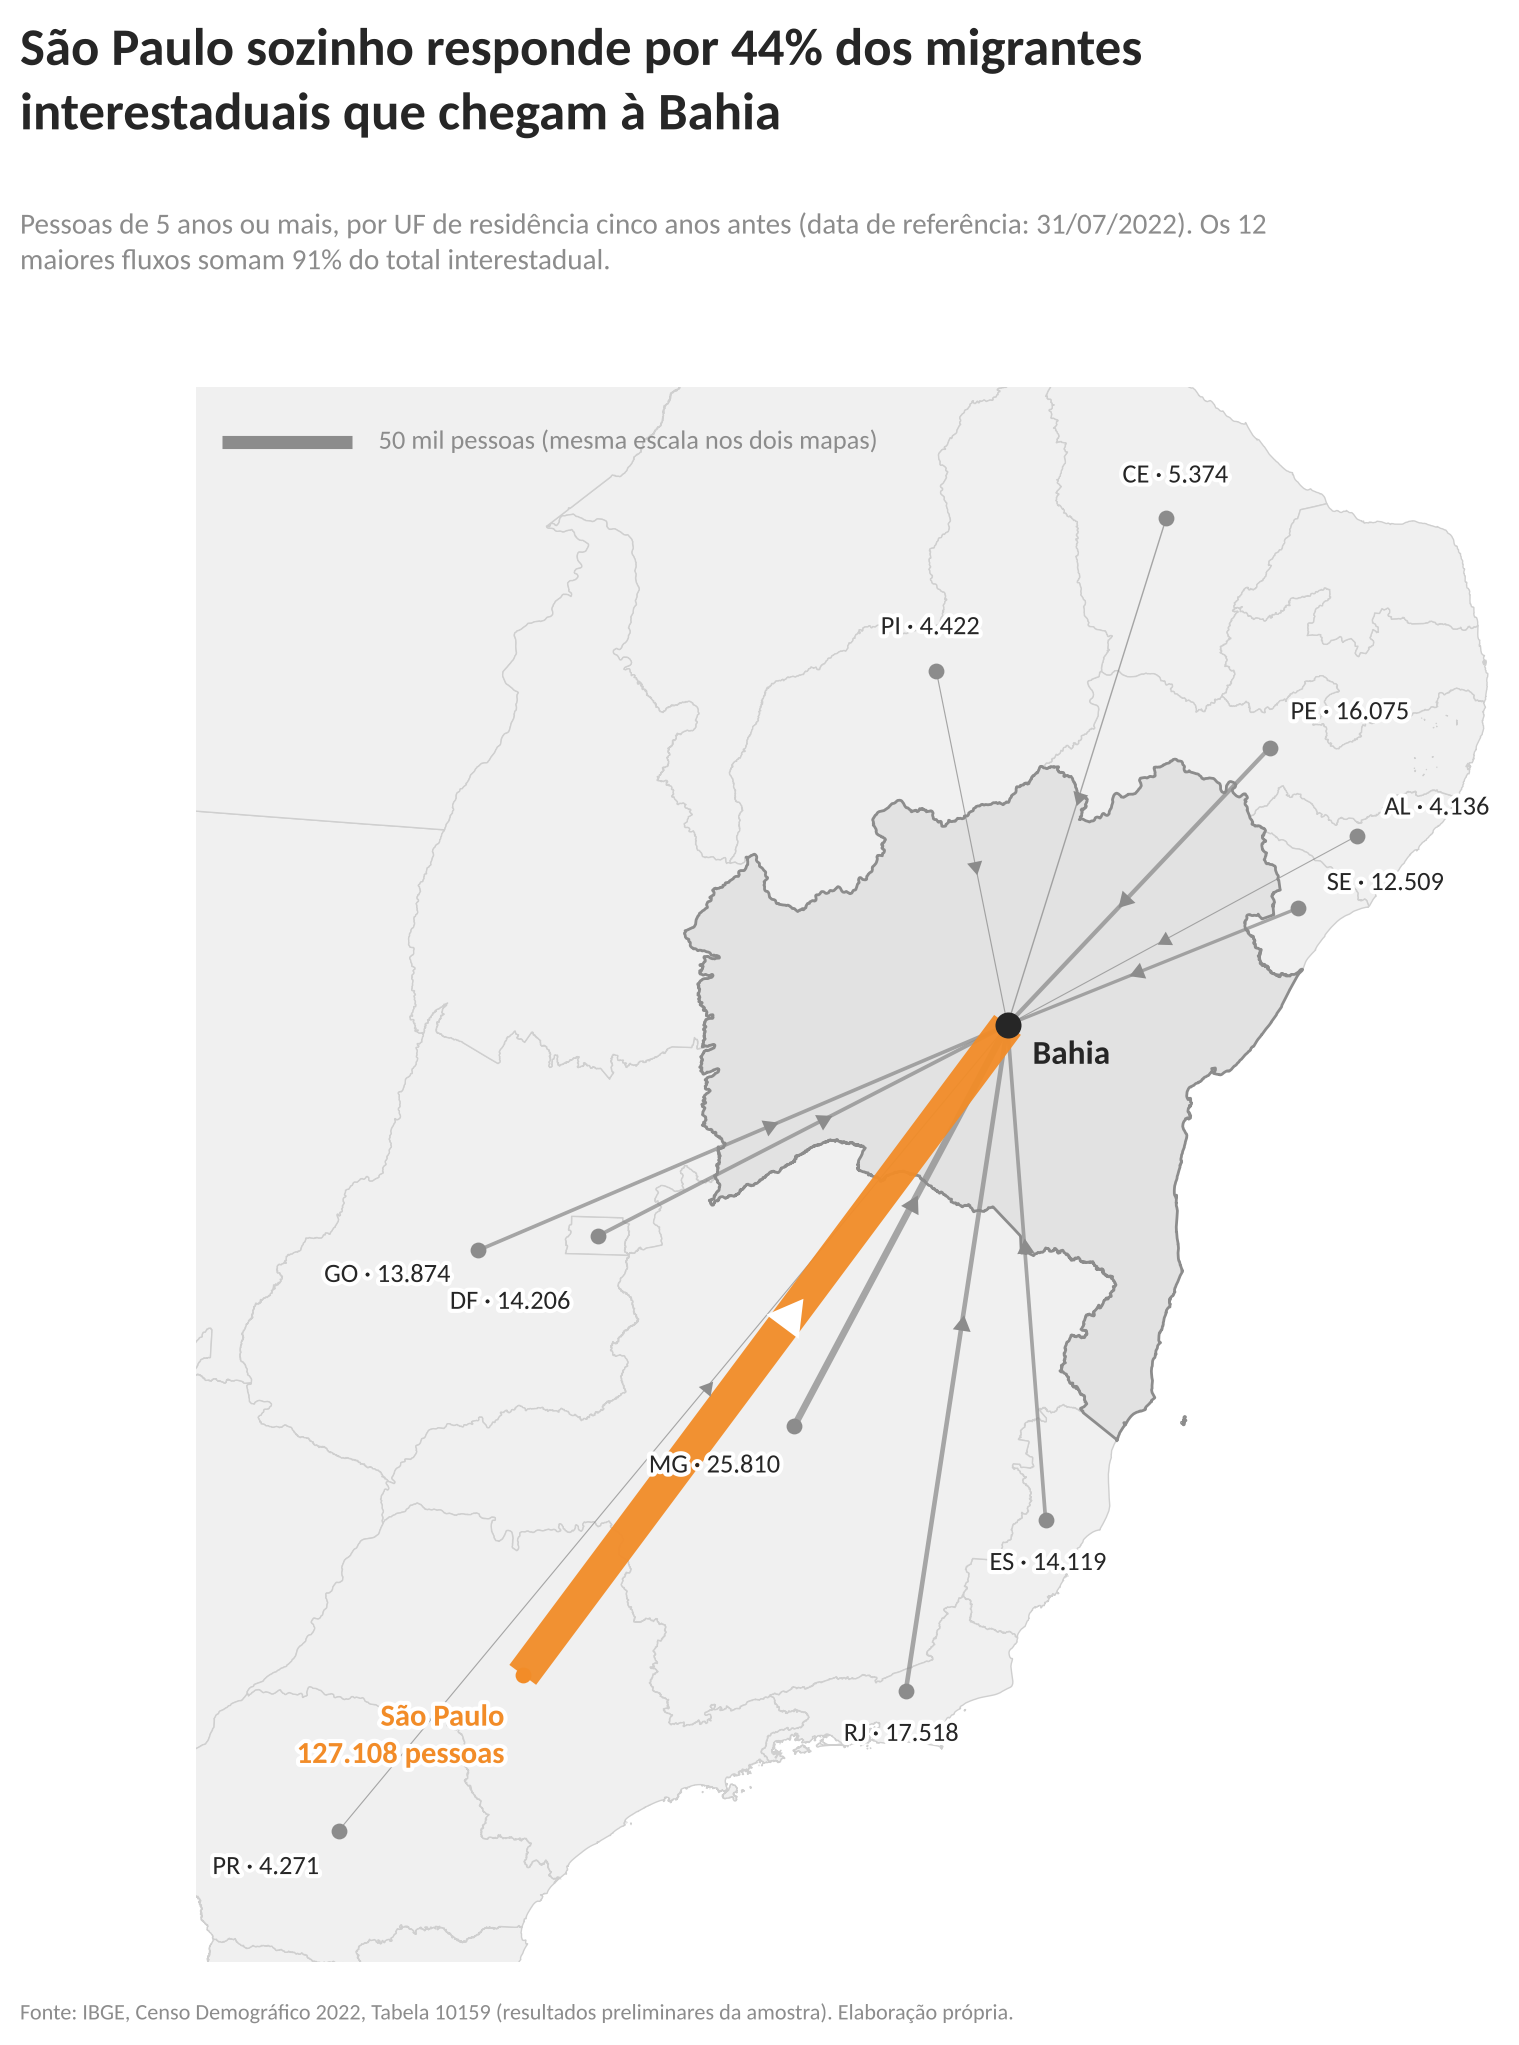

In [6]:
SUB = (f'Pessoas de 5 anos ou mais, por UF de residência cinco anos antes (data de referência: 31/07/2022). '
       f'Os {TOP_N} maiores fluxos somam {{pct:.0%}} do total interestadual.')
mapa_fluxo(fluxos_entrada, 'entrada', manchete_fluxo(entradas, fluxos_entrada, 'entrada'),
           SUB.format(pct=fluxos_entrada.pessoas.sum() / entradas.pessoas.sum()), 'figs/fluxo_entrada_bahia.png')
plt.show()

### 5.2 Mapa 2 — Saídas: para onde vão
Pessoas que **moravam na Bahia cinco anos antes** e residiam em outra UF em 31/07/2022. As linhas partem da Bahia.

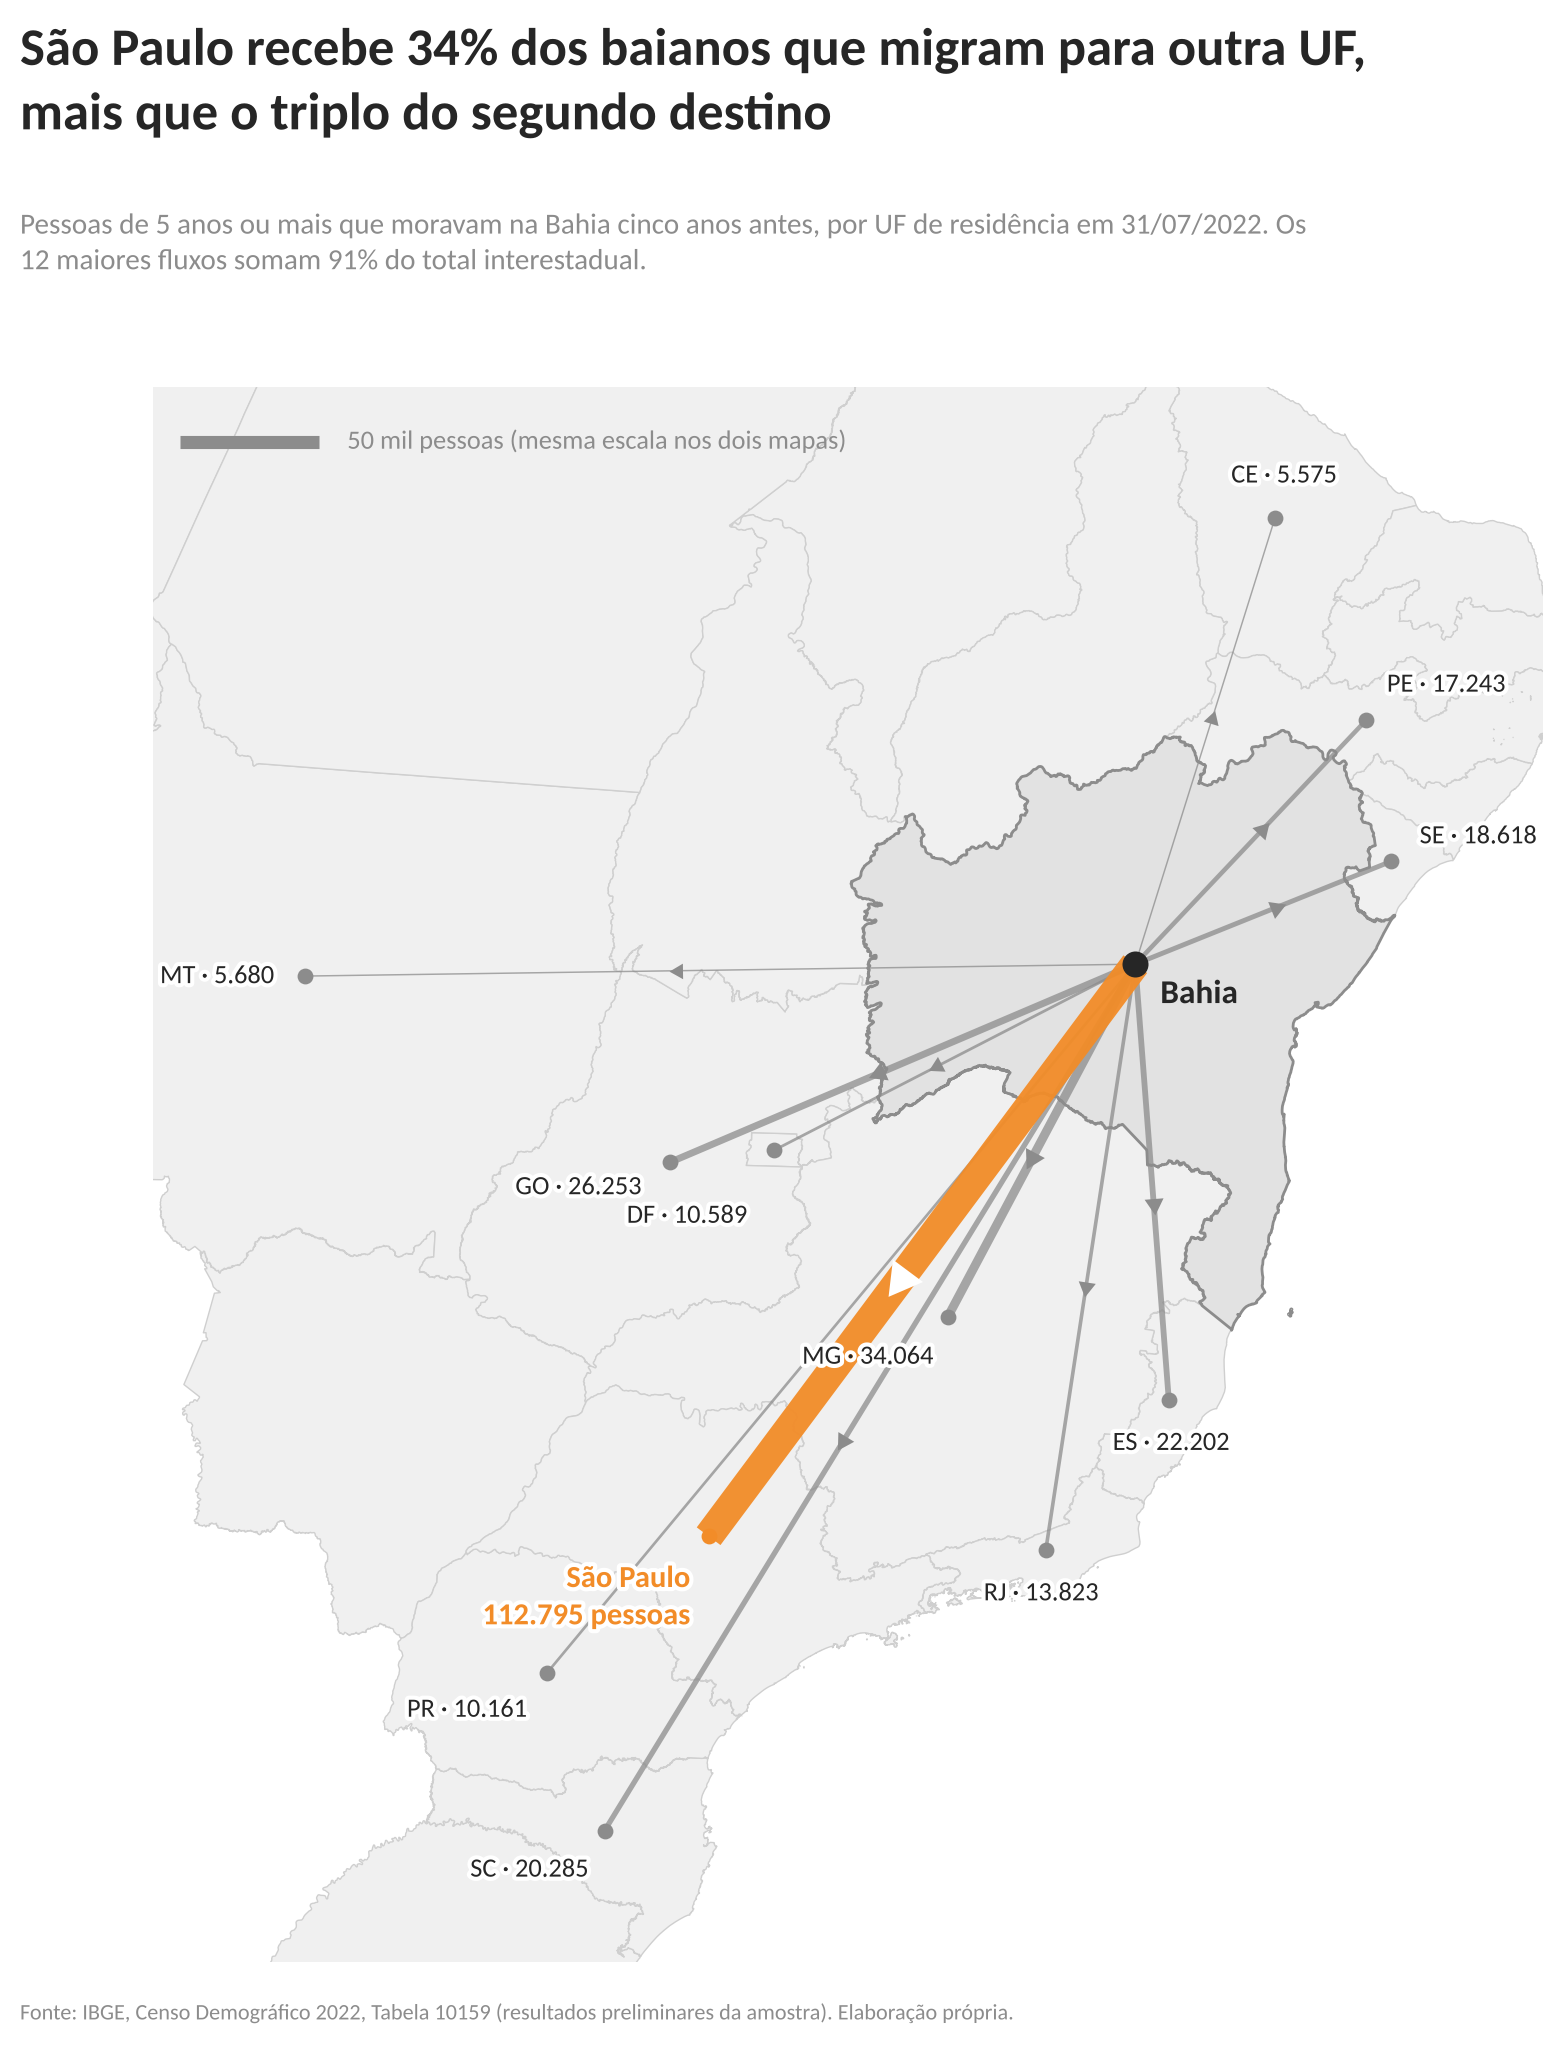

In [7]:
SUB2 = (f'Pessoas de 5 anos ou mais que moravam na Bahia cinco anos antes, por UF de residência em 31/07/2022. '
        f'Os {TOP_N} maiores fluxos somam {{pct:.0%}} do total interestadual.')
mapa_fluxo(fluxos_saida, 'saida', manchete_fluxo(saidas, fluxos_saida, 'saida'),
           SUB2.format(pct=fluxos_saida.pessoas.sum() / saidas.pessoas.sum()), 'figs/fluxo_saida_bahia.png')
plt.show()

> **Rótulos:** UFs vizinhas (por exemplo SE, AL e PE) podem ficar com rótulos próximos. Se isso ocorrer, afaste-os com `ajustes={'SE': (0, -8), ...}` (deslocamento em pontos) ao chamar `mapa_fluxo`.

## 6. Boas práticas
**Erros comuns em mapas de fluxo** (e como os evitamos):
1. **Mostrar todos os fluxos (espaguete)** — filtramos os `TOP_N` maiores e declaramos quanto do total eles cobrem.
2. **Largura que não é proporcional** — reescalar de mínimo a máximo faz a menor linha parecer "grande". Aqui `largura = k × pessoas`, a partir de zero, com o mesmo `k` nos dois mapas.
3. **Uma cor por origem** — só cinza e um destaque (o maior fluxo).
4. **Direção ambígua** — marcador triangular no meio de cada linha.
5. **Legenda em caixa** — rótulos diretos nas UFs e uma chave de largura anotada.
6. **Linha reta lida como rota** — avisamos que liga pontos representativos.

### 6.1 Redesenho: antes e depois
O "antes" abaixo reúne os erros 1, 3 e 5: **todos** os fluxos, uma cor por UF, legenda em caixa e título genérico.

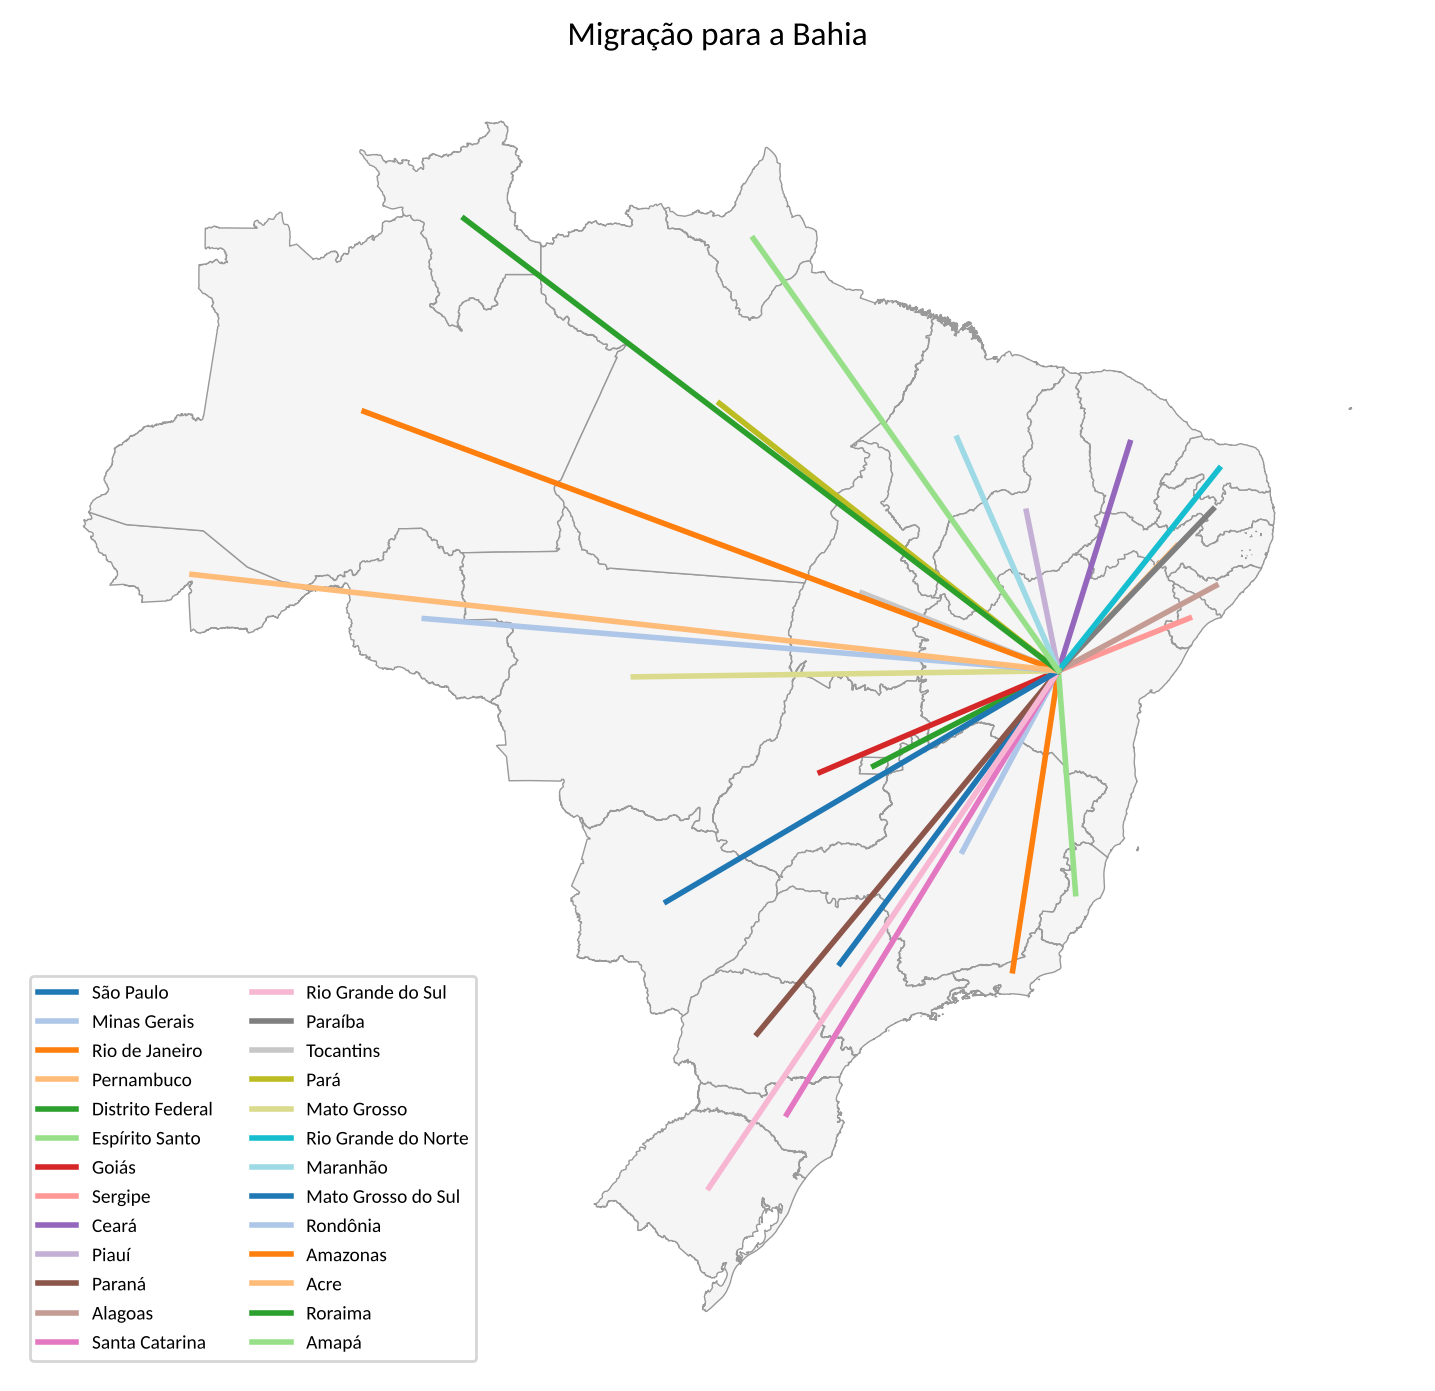

In [8]:
def antes_fluxo(tab, arquivo='figs/fluxo_ANTES.png'):
    with mpl.rc_context({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'text.color': 'black'}):
        fig, ax = plt.subplots(figsize=(9, 9), facecolor='white'); ax.set_aspect('equal')
        if estados is not None:
            estados.plot(ax=ax, color='#F5F5F5', edgecolor='#999999', linewidth=0.5)
        xb, yb = pontos[BAHIA]
        cmap = plt.get_cmap('tab20')
        for k, (_, f) in enumerate(tab.iterrows()):                 # TODOS os fluxos positivos
            xu, yu = pontos[f['origem']]
            ax.plot([xu, xb], [yu, yb], color=cmap(k % 20), lw=2, label=f['origem'])
        ax.legend(fontsize=7, ncol=2, loc='lower left'); ax.set_title('Migração para a Bahia'); ax.axis('off')
        fig.savefig(arquivo, dpi=150, facecolor='white')
    return fig

antes_fluxo(entradas); plt.show()

**Depois:** a figura da seção 5.1 (`figs/fluxo_entrada_bahia.png`). Nos slides, coloquem as duas lado a lado e anotem o que mudou (de 26 linhas coloridas para 12 cinzas com um destaque; largura proporcional; rótulos diretos; manchete; fonte).

## 7. Alternativas
| Alternativa | Responde bem | Custo |
|---|---|---|
| **Mapa de fluxo radial (esta técnica)** | de onde para onde, com a geografia | linhas retas não são rotas; vizinhos próximos se sobrepõem |
| **Gráfico de barras** (saldo por UF) | **quanto** cada UF ganha ou perde, com valores exatos | some o mapa: o leitor não vê a geografia |
| **Mapa coroplético** do saldo | onde fica cada UF | só mostra um valor por UF e esconde a ligação com a Bahia |
| **Matriz (mapa de calor) origem × destino** | todos os pares de UFs de uma vez | pouco intuitiva e densa (27 × 27) |

A alternativa implementada responde a uma pergunta que o mapa de fluxo não responde bem: **quanto cada UF ganha ou perde no saldo**.

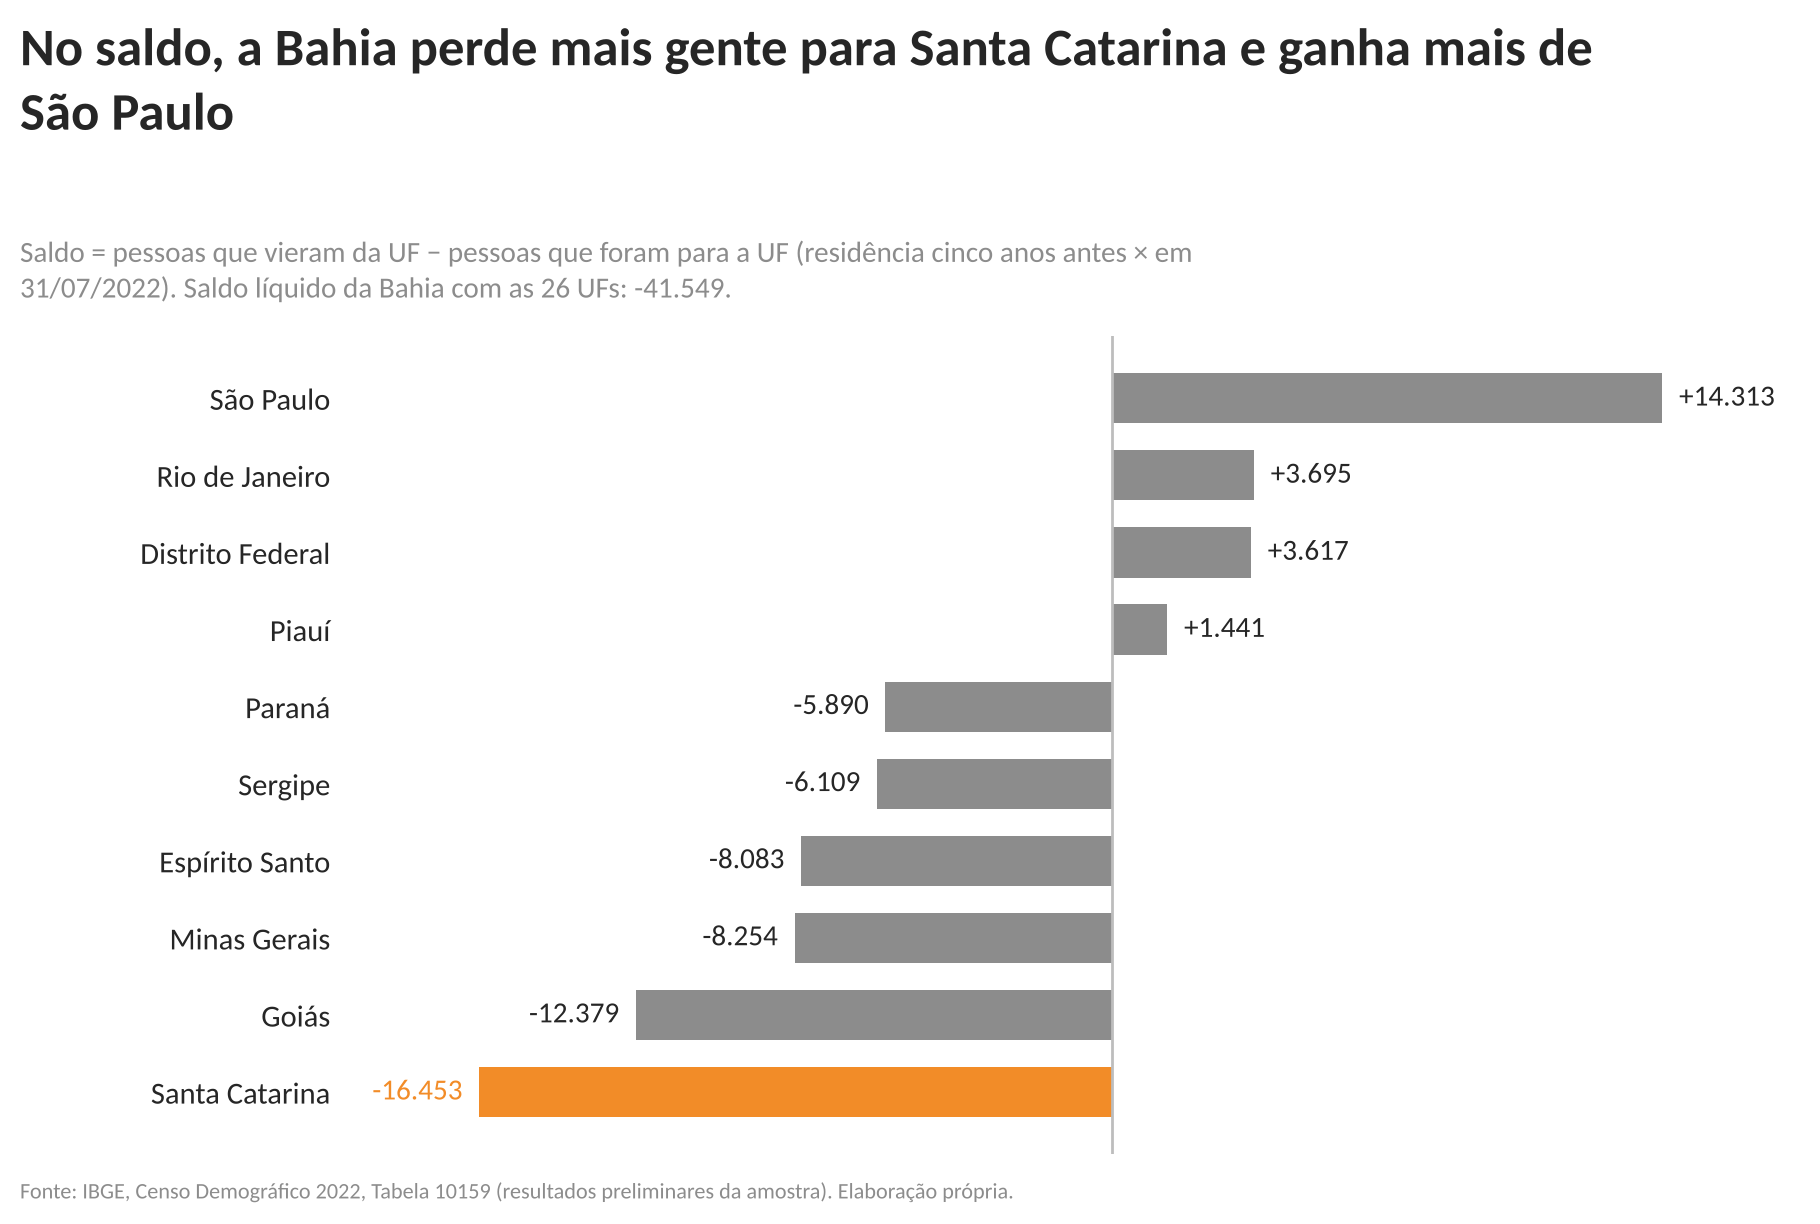

In [9]:
def barras_saldo(n_neg=6, n_pos=4, arquivo='figs/fluxo_saldo_liquido.png'):
    # saldo = pessoas que vieram da UF − pessoas que foram para a UF (positivo: a Bahia ganha)
    saldo = pd.Series(matriz.loc[BAHIA, OUTRAS].to_numpy() - matriz.loc[OUTRAS, BAHIA].to_numpy(), index=OUTRAS)
    sel = pd.concat([saldo.nsmallest(n_neg), saldo.nlargest(n_pos)]).sort_values()
    neg, pos = saldo.idxmin(), saldo.idxmax()
    fig, ax = plt.subplots(figsize=(10, 6.2)); fig.subplots_adjust(top=0.72, bottom=0.06, left=0.20, right=0.93)
    cores = [DESTAQUE if u == neg else CINZA for u in sel.index]
    ax.barh(sel.index, sel.values, color=cores, height=0.65)
    ax.axvline(0, color=CINZA_ESC, lw=1)
    for u, v in sel.items():
        ax.annotate(f'{v:+,.0f}'.replace(',', '.'), (v, u), xytext=(6 if v > 0 else -6, 0), textcoords='offset points',
                    ha='left' if v > 0 else 'right', va='center', fontsize=10.5, color=DESTAQUE if u == neg else TXT)
    ax.set_xlim(sel.min() * 1.22, sel.max() * 1.25)
    ax.tick_params(axis='y', length=0, labelsize=11, labelcolor=TXT); ax.set_xticks([])
    for sp in ['top', 'right', 'bottom', 'left']: ax.spines[sp].set_visible(False)
    moldura(fig, f'No saldo, a Bahia perde mais gente para {neg} e ganha mais de {pos}',
            f'Saldo = pessoas que vieram da UF − pessoas que foram para a UF (residência cinco anos antes × em 31/07/2022). Saldo líquido da Bahia com as 26 UFs: {saldo.sum():+,.0f}.'.replace(',', '.'),
            larg=72, y_sub=0.80)
    fig.savefig(arquivo, dpi=200)
    return fig

barras_saldo(); plt.show()

## 8. Tabelas dos fluxos representados

In [10]:
display(fluxos_entrada.style.format({'pessoas': '{:,.0f}'}))
display(fluxos_saida.style.format({'pessoas': '{:,.0f}'}))
fluxos_entrada.to_csv('fluxos_entrada_bahia.csv', index=False, encoding='utf-8-sig')
fluxos_saida.to_csv('fluxos_saida_bahia.csv', index=False, encoding='utf-8-sig')

,origem,destino,pessoas
0,São Paulo,Bahia,"127,108"
1,Minas Gerais,Bahia,"25,810"
2,Rio de Janeiro,Bahia,"17,518"
3,Pernambuco,Bahia,"16,075"
4,Distrito Federal,Bahia,"14,206"
5,Espírito Santo,Bahia,"14,119"
6,Goiás,Bahia,"13,874"
7,Sergipe,Bahia,"12,509"
8,Ceará,Bahia,"5,374"
9,Piauí,Bahia,"4,422"


,origem,destino,pessoas
0,Bahia,São Paulo,"112,795"
1,Bahia,Minas Gerais,"34,064"
2,Bahia,Goiás,"26,253"
3,Bahia,Espírito Santo,"22,202"
4,Bahia,Santa Catarina,"20,285"
5,Bahia,Sergipe,"18,618"
6,Bahia,Pernambuco,"17,243"
7,Bahia,Rio de Janeiro,"13,823"
8,Bahia,Distrito Federal,"10,589"
9,Bahia,Paraná,"10,161"


## 9. Cuidados metodológicos
- **Migração por data fixa:** compara a UF de residência cinco anos antes de 31/07/2022 com a UF de residência na data de referência. Quem se mudou mais de uma vez no período aparece só uma vez, com origem e destino finais; quem voltou ao lugar de origem não aparece como migrante.
- **Valores são pessoas, não taxas:** UFs muito populosas tendem a ter fluxos maiores. Para comparar intensidade, use taxas por habitante.
- **Resultados preliminares da amostra** (aba *Notas* da planilha): os números são estimativas.
- **Fora dos mapas:** Exterior, Brasil sem especificação e Sem declaração. Os `TOP_N` maiores fluxos omitem os menores (a cobertura é informada no subtítulo).
- **Linhas retas** ligam centroides das UFs; não são trajetos.

## 10. Mensagens principais e referências
- O mapa de fluxo responde **de onde para onde**; para **quanto**, as barras são mais precisas. Combine os dois.
- Filtrar os maiores fluxos e manter a largura proporcional evita o espaguete sem esconder o que domina.

**Referências**
- Schwabish, J. *Better Data Visualizations*. Columbia University Press, 2021. Cap. 7, p. 245–248 (mapas de fluxo).
- Rendgen, S. *The Minard System*. Princeton Architectural Press, 2018 (citado no livro).
- IBGE. *Censo Demográfico 2022* — SIDRA, Tabela 10159. Acesso em 16/11/2026.
- IBGE. *Malhas Territoriais — Unidades da Federação 2022*.